<a href="https://colab.research.google.com/github/Athenessa/bangkok-flood-data-analytics/blob/main/data_group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving EDA.xlsx to EDA.xlsx


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ใช้ชื่อไฟล์ที่เพิ่งอัปโหลด
filename = next(iter(uploaded))

# ตรวจว่ามีชีตอะไรบ้าง
excel = pd.ExcelFile(filename)
print("รายชื่อชีต:", excel.sheet_names)

# อ่านเฉพาะชีตข้อมูลน้ำท่วม
df = pd.read_excel(filename, sheet_name="flood")

# จัดรูปแบบวันที่
df["date"] = pd.to_datetime(df["date"], errors="coerce")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("จำนวนรายการ:", len(df))
display(df.head())

รายชื่อชีต: ['data check and notes', 'districts', 'impact_2011vs2026', 'flood', 'stat_input', 'Analysis', 'budget', 'district_events', 'year_over_3h', 'month_events', 'EDA_Complete', 'EDA_Stats', 'EDA_Distribution', 'EDA_Filter', 'EDA_Matrix', 'EDA_Correlation', 'impact_events', 'impact_2026', 'impact_2011', 'flood_pattern_budget', 'flood_pattern_budget_share']
จำนวนรายการ: 841


,id,date,month,season,year,district,location_raw,location_raw_clean,location,location_clean,...,start_time,start_time_hr,end_time_text,end_time,duration_min,duration_check,duration_over_3h,rain_mm,dup_key,dup_count
0,1,2024-03-20,3,Dry,2024,พระนคร,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,ถนนมหาราช วัดโพธิ์,...,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.5,2024-03-20|พระนคร|ถนนมหาราช วัดโพธิ์|8:15 น.,1
1,2,2024-03-20,3,Dry,2024,ป้อมปราบศัตรูพ่าย,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,ถนนเสือป่า แยกวรจักร,...,08:15:00,8,8:50 น.,08:50:00,35,True,No,50.5,2024-03-20|ป้อมปราบศัตรูพ่าย|ถนนเสือป่า แยกวรจ...,1
2,3,2024-03-20,3,Dry,2024,หลักสี่,ถนนแจ้งวัฒนะ ช่วงแจ้งวัฒนะซอย10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10,...,09:00:00,9,9:45 น.,09:45:00,45,True,No,50.0,2024-03-20|หลักสี่|ถนนแจ้งวัฒนะซ.แจ้งวัฒนะ10|9...,1
3,4,2024-03-20,3,Dry,2024,ดินแดง,ถนนประชาสงเคราะห์ ช่วงตลาดเช้า,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,ถนนประชาสงเคราะห์,...,08:10:00,8,8:55 น.,08:55:00,45,True,No,52.5,2024-03-20|ดินแดง|ถนนประชาสงเคราะห์|8:10 น.,1
4,5,2024-03-20,3,Dry,2024,บางแค,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,ถนนเพชรเกษม หน้าวัดประดู่,...,08:30:00,8,9:25 น.,09:25:00,55,True,No,90.5,2024-03-20|บางแค|ถนนเพชรเกษม หน้าวัดประดู่|8:3...,1


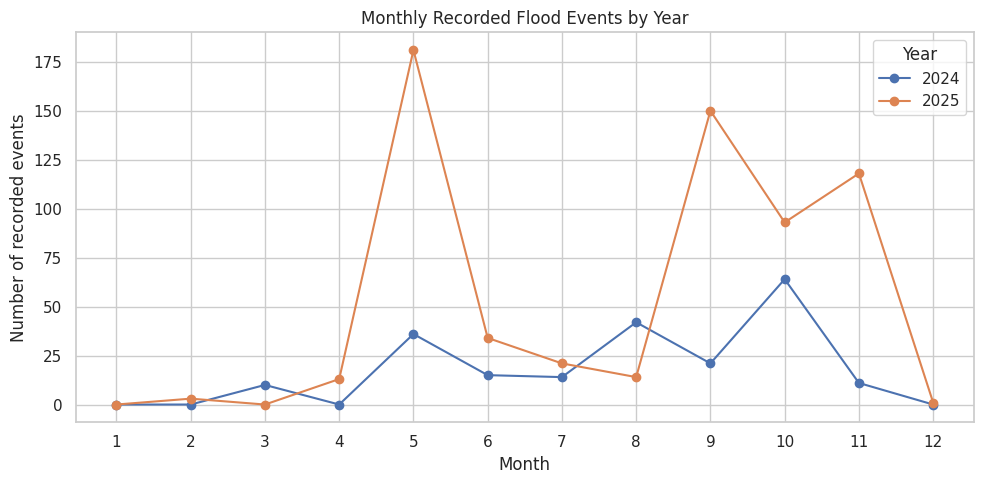

In [ ]:
monthly = pd.crosstab(df["month"], df["year"])
monthly = monthly.reindex(range(1, 13), fill_value=0)

ax = monthly.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

ax.set_title("Monthly Recorded Flood Events by Year")
ax.set_xlabel("Month")
ax.set_ylabel("Number of recorded events")
ax.set_xticks(range(1, 13))
ax.legend(title="Year")

plt.tight_layout()
plt.savefig("fig1_monthly_events.png", dpi=300, bbox_inches="tight")
plt.show()

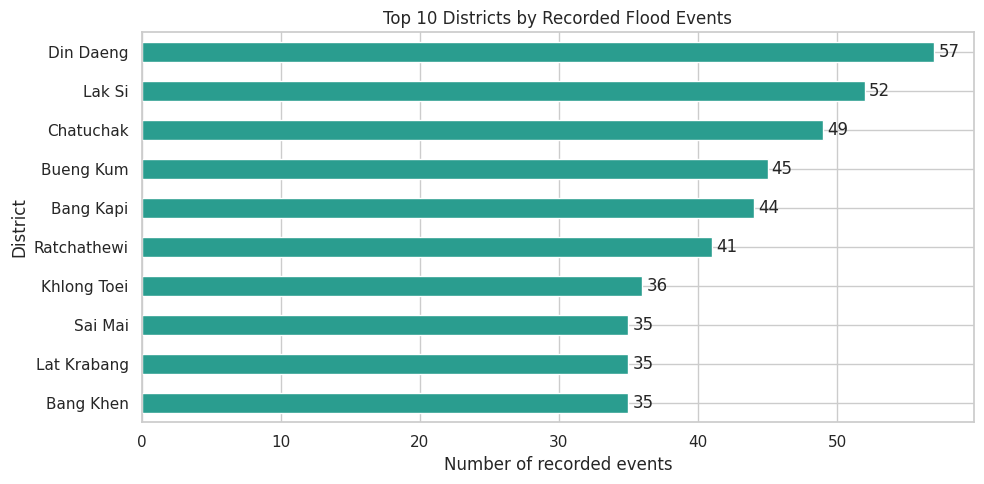

In [ ]:
districts = pd.read_excel(filename, sheet_name="districts")

district_names = districts.set_index("district_th")["district_en"]
df["district_en"] = df["district"].map(district_names)

top10 = (
    df["district_en"]
    .value_counts()
    .head(10)
    .sort_values()
)

ax = top10.plot.barh(color="#2A9D8F")

ax.set_title("Top 10 Districts by Recorded Flood Events")
ax.set_xlabel("Number of recorded events")
ax.set_ylabel("District")
ax.set_xlim(left=0)

for i, value in enumerate(top10):
    ax.text(value + 0.3, i, str(value), va="center")

plt.tight_layout()
plt.savefig("fig2_top10_districts.png", dpi=300, bbox_inches="tight")
plt.show()

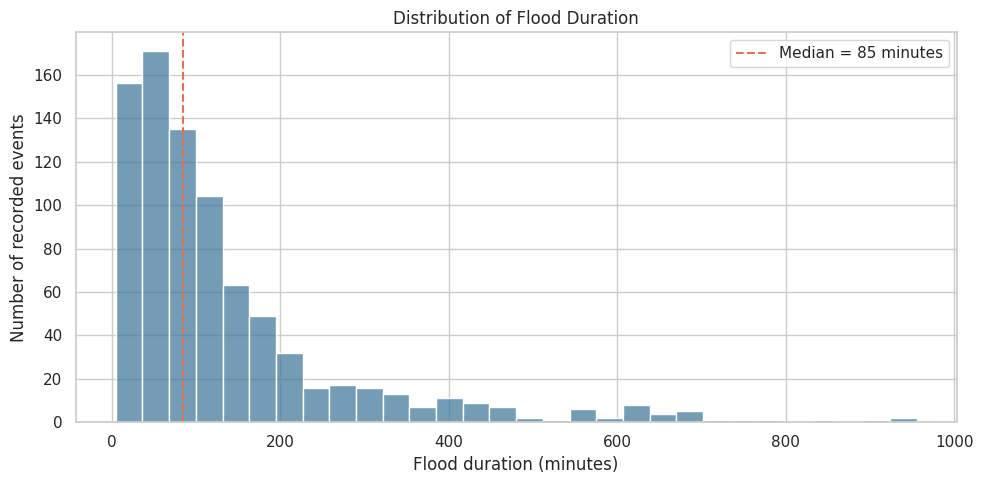

In [ ]:
duration = pd.to_numeric(df["duration_min"], errors="coerce").dropna()

sns.histplot(duration, bins=30, color="#457B9D")

plt.axvline(
    duration.median(),
    color="#E76F51",
    linestyle="--",
    label=f"Median = {duration.median():.0f} minutes"
)

plt.title("Distribution of Flood Duration")
plt.xlabel("Flood duration (minutes)")
plt.ylabel("Number of recorded events")
plt.legend()

plt.tight_layout()
plt.savefig("fig3_duration_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

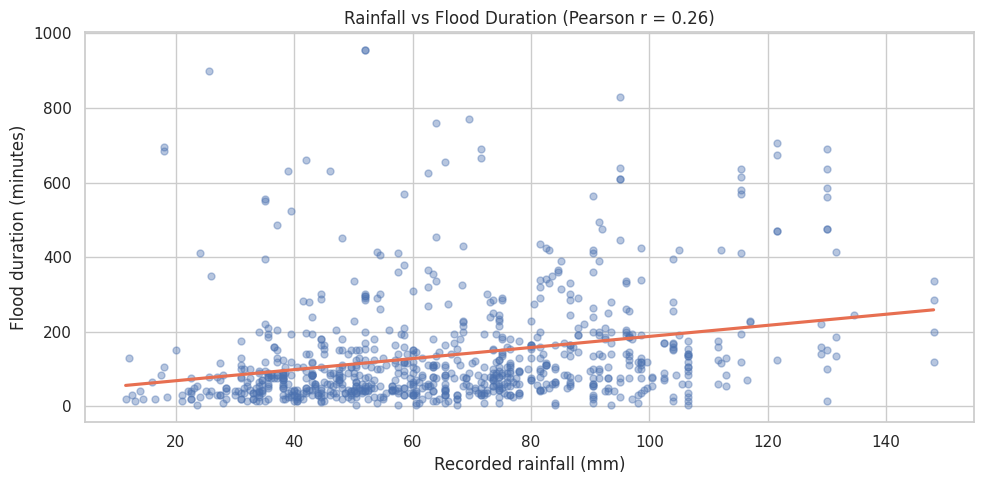

จำนวนรายการที่ใช้: 841
Pearson r: 0.265


In [ ]:
pair = df[["rain_mm", "duration_min"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

sns.regplot(
    data=pair,
    x="rain_mm",
    y="duration_min",
    ci=None,
    scatter_kws={"alpha": 0.4, "s": 25},
    line_kws={"color": "#E76F51"}
)

r = pair["rain_mm"].corr(pair["duration_min"])

plt.title(f"Rainfall vs Flood Duration (Pearson r = {r:.2f})")
plt.xlabel("Recorded rainfall (mm)")
plt.ylabel("Flood duration (minutes)")

plt.tight_layout()
plt.savefig("fig4_rainfall_duration.png", dpi=300, bbox_inches="tight")
plt.show()

print("จำนวนรายการที่ใช้:", len(pair))
print("Pearson r:", round(r, 3))

In [ ]:
import zipfile

figures = [
    "fig1_monthly_events.png",
    "fig2_top10_districts.png",
    "fig3_duration_distribution.png",
    "fig4_rainfall_duration.png",
]

with zipfile.ZipFile("Part5_Figures.zip", "w") as z:
    for figure in figures:
        z.write(figure)

files.download("Part5_Figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>